# PN dataset using the four-channel NGC 253 background estimate

Each sample contains:

- a 64×64 crop from the estimated diffuse NGC 253 background;
- the corresponding four-channel observational-error crop;
- zero, one, or two unresolved PNe;
- independently sampled unresolved HII-region and SNR distractors;
- one complete emission-line model spectrum selected for each injected source;
- a Moffat PSF shared by all compact sources within a patch;
- a PN-centre heatmap target (HII/SNR sources are not included in the target).

The minimum separation between all injected compact sources is sampled independently
for each patch from a uniform distribution between 3 and 15 pixels.

The background is read directly from the output of `bkg_estimation_4channel.ipynb`:

```text
NGC253_background_and_errors.npz
```

The four network-input channels are:

```text
Hbeta, OIII5007, Halpha, NII6584
```

The input shape is:

```text
(number of samples, 4, 64, 64)
```

The target shape is:

```text
(number of samples, 1, 64, 64)
```

Noise is added **after** PN/HII/SNR injection, using the corresponding smoothed
observational-error map as the per-pixel Gaussian sigma for each line.


In [35]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import extinction

In [36]:
# ============================================================
# Configuration
# ============================================================

SEED = 42

MODEL_CSV = "../models_constrained_OI.csv"
BACKGROUND_NPZ = "background_and_errors.npz"

PATCH_SIZE = 64
USED_LINES = ["Hbeta", "OIII5007", "Halpha", "NII6584"]

MODEL_COLUMNS = {
    "Hbeta": "H__1__4861A",
    "OIII4959": "O__3__4959A",
    "OIII5007": "O__3__5007A",
    "Halpha": "H__1__6563A",
    "NII6584": "N__2__6584A",
}

LINE_WAVELENGTHS = {
    "Hbeta": 4861.33,
    "OIII5007": 5006.84,
    "Halpha": 6562.80,
    "NII6584": 6583.45,
}

# Keys written by bkg_estimation_4channel.ipynb
BACKGROUND_KEYS = {
    "Hbeta": "hb_background",
    "OIII5007": "oiii_background",
    "Halpha": "ha_background",
    "NII6584": "nii_background",
}

ERROR_KEYS = {
    "Hbeta": "hb_error",
    "OIII5007": "oiii_error",
    "Halpha": "ha_error",
    "NII6584": "nii_error",
}

# MUSE-like spatial sampling and PSF
PIXEL_SCALE_ARCSEC = 0.2

PSF_FWHM_MEAN_ARCSEC = 0.8
PSF_FWHM_STD_ARCSEC = 0.2
PSF_FWHM_LIMITS_ARCSEC = (0.5, 1.2)
MOFFAT_BETA = 2.8

# Brightness ranges.
# Keeping HII/SNR on the same observed OIII5007 magnitude range as the PNe
# prevents the network from solving the task from brightness alone.
PN_M5007_RANGE = (22, 28.0)
HII_M5007_RANGE = (22, 28.0)
SNR_M5007_RANGE = (22, 28.0)

SOURCE_MARGIN_PIX = 5.0

# Draw ONE minimum source separation for each sample.
MINIMUM_SOURCE_SEPARATION_RANGE_PIX = (5.0, 15.0)

# Heatmap target -- only PN positions are used.
LABEL_SIGMA_PIX = 1.0

# If True, draw a new valid 64x64 background crop for every sample.
# If False, all samples use the same crop selected below.
REGENERATE_BACKGROUND_PER_SAMPLE = True

EXTINCTION_RV = 3.1
EBV_MODE = "normal"

# Keep exactly the original PN count distribution: 0, 1, or 2 PNe per patch.
PN_NUMBERS = [0, 1, 2]
PN_PROBABILITIES = [0.25, 0.5, 0.25]

# Default distractor counts. These are independent of the PN count.
# Change these if you want fewer/more contaminants.
HII_NUMBERS = [0, 1, 2]
HII_PROBABILITIES = [0.25, 0.5, 0.25]

SNR_NUMBERS = [0, 1, 2]
SNR_PROBABILITIES = [0.25, 0.5, 0.25]


## Load the PN models

Only the PN rows are needed by the synthesizer. The background is supplied by the four-channel background-estimation product.


In [37]:
models = pd.read_csv(MODEL_CSV)

if "class" not in models.columns:
    raise ValueError("MODEL_CSV must contain a 'class' column.")

model_classes = models["class"].astype(str).str.strip().str.upper()

pn_models = models[model_classes == "PN"].reset_index(drop=True)
hii_models = models[model_classes == "HII"].reset_index(drop=True)
snr_models = models[model_classes == "SNR"].reset_index(drop=True)

missing = []
if len(pn_models) == 0:
    missing.append("PN")
if len(hii_models) == 0:
    missing.append("HII")
if len(snr_models) == 0:
    missing.append("SNR")

if missing:
    available = sorted(models["class"].dropna().astype(str).unique().tolist())
    raise ValueError(
        f"No model rows found for class(es): {missing}. "
        f"Available class values are: {available}"
    )

print("# PN: ", len(pn_models))
print("# HII:", len(hii_models))
print("# SNR:", len(snr_models))


# PN:  216
# HII: 451
# SNR: 296


In [38]:
def sample_ngc253_ebv(rng, mode="normal"):
    if mode == "fixed":
        return 0.36

    if mode == "normal":
        ebv = rng.normal(loc=0.36, scale=0.25)
        return float(np.clip(ebv, 0.0, 2.5))

    if mode == "lognorm":
        ebv = rng.lognormal(mean=np.log(0.36), sigma=0.5)
        return float(np.clip(ebv, 0.0, 2.5))

In [39]:
def m5007_to_flux(m5007):
    # erg s^-1 cm^-2
    return 10.0 ** (-0.4 * (m5007 + 13.74))


# Scale one intrinsic model row to an observed [O III] 5007 flux and apply
# O'Donnell extinction to the line ratios.
# The selected m5007 is treated as the observed magnitude.
# The final [O III] 5007 flux remains exactly equal to m5007_to_flux(m5007).
def scale_model_from_m5007(model_row, m5007, ebv, rv=3.1):
    observed_f5007 = m5007_to_flux(m5007)

    model_f5007 = float(model_row[MODEL_COLUMNS["OIII5007"]])

    if not np.isfinite(model_f5007) or model_f5007 <= 0:
        raise ValueError("The selected model has invalid [O III] 5007 flux.")

    # Intrinsic line ratios relative to [O III] 5007
    intrinsic_ratios = np.array(
        [
            float(model_row[MODEL_COLUMNS[line_name]]) / model_f5007
            for line_name in USED_LINES
        ],
        dtype=float,
    )

    wavelengths = np.array(
        [LINE_WAVELENGTHS[line_name] for line_name in USED_LINES],
        dtype=float,
    )

    av = rv * ebv

    # A_lambda in magnitudes
    a_lambda = extinction.odonnell94(
        wavelengths,
        av,
        rv,
        unit="aa",
    )
    a_5007 = extinction.odonnell94(
        np.array([LINE_WAVELENGTHS["OIII5007"]]),
        av,
        rv,
        unit="aa",
    )[0]

    # Differential attenuation relative to [O III] 5007
    relative_attenuation = 10.0 ** (-0.4 * (a_lambda - a_5007))

    observed_ratios = intrinsic_ratios * relative_attenuation

    return {
        line_name: float(observed_f5007 * observed_ratio)
        for line_name, observed_ratio in zip(USED_LINES, observed_ratios)
    }


In [40]:
def sample_truncated_normal(rng, mean, standard_deviation, limits):
    lower, upper = limits

    while True:
        value = rng.normal(mean, standard_deviation)

        if lower <= value <= upper:
            return value


def normalized_moffat_psf(ny, nx, x0, y0, fwhm_pix, beta):
    yy, xx = np.mgrid[:ny, :nx]

    alpha = fwhm_pix / (2.0 * np.sqrt(2.0 ** (1.0 / beta) - 1.0))

    radius_squared = (xx - x0) ** 2 + (yy - y0) ** 2

    psf = (1.0 + radius_squared / alpha**2) ** (-beta)

    psf /= psf.sum()

    return psf.astype(np.float32)


def make_centre_heatmap(ny, nx, positions, sigma_pix):
    yy, xx = np.mgrid[:ny, :nx]

    heatmap = np.zeros((ny, nx), dtype=np.float32)

    for x0, y0 in positions:
        source_heatmap = np.exp(
            -0.5 * ((xx - x0) ** 2 + (yy - y0) ** 2) / sigma_pix**2
        )

        # Guarantee maximum = 1
        source_heatmap /= source_heatmap.max()

        heatmap = np.maximum(heatmap, source_heatmap)

    return heatmap.astype(np.float32)


def choose_source_positions(
    n_sources,
    patch_size,
    margin_pix,
    minimum_separation_pix,
    rng,
    max_attempts=5000,
):
    """Place all compact sources with the requested pairwise minimum separation."""

    positions = []
    attempts = 0

    while len(positions) < n_sources and attempts < max_attempts:
        attempts += 1

        x0 = rng.uniform(margin_pix, patch_size - 1 - margin_pix)
        y0 = rng.uniform(margin_pix, patch_size - 1 - margin_pix)

        far_enough = all(
            np.hypot(x0 - x1, y0 - y1) >= minimum_separation_pix
            for x1, y1 in positions
        )

        if far_enough:
            positions.append((x0, y0))

    if len(positions) != n_sources:
        raise RuntimeError(
            f"Could not place {n_sources} compact sources with "
            f"minimum separation {minimum_separation_pix:.2f} pix."
        )

    return positions


def inject_psf_model_source(
    output_maps,
    model_row,
    position,
    source_class,
    m5007_range,
    psf_fwhm_arcsec,
    psf_fwhm_pix,
    rng,
):
    """Inject one PN/HII/SNR model as an unresolved Moffat-PSF source."""

    x0, y0 = position

    m5007 = float(rng.uniform(*m5007_range))

    ebv = sample_ngc253_ebv(
        rng=rng,
        mode=EBV_MODE,
    )

    line_fluxes = scale_model_from_m5007(
        model_row=model_row,
        m5007=m5007,
        ebv=ebv,
        rv=EXTINCTION_RV,
    )

    psf = normalized_moffat_psf(
        ny=PATCH_SIZE,
        nx=PATCH_SIZE,
        x0=x0,
        y0=y0,
        fwhm_pix=psf_fwhm_pix,
        beta=MOFFAT_BETA,
    )

    for channel, line_name in enumerate(USED_LINES):
        output_maps[channel] += (
            line_fluxes[line_name] * psf
        ).astype(np.float32)

    model_id = (
        str(model_row["model_id"])
        if "model_id" in model_row.index
        else str(model_row.name)
    )

    return {
        "class": source_class,
        "x": float(x0),
        "y": float(y0),
        "model_id": model_id,
        "m5007": float(m5007),
        "ebv": float(ebv),
        "rv": float(EXTINCTION_RV),
        "psf_fwhm_arcsec": float(psf_fwhm_arcsec),
        "psf_fwhm_pix": float(psf_fwhm_pix),
        "line_fluxes": {
            line_name: float(flux)
            for line_name, flux in line_fluxes.items()
        },
    }


## Load the four-channel diffuse background and error maps

The background-estimation notebook has already removed compact/bright emission-line sources from the background fit and saved smooth diffuse-background maps. Therefore the synthesizer does not generate a separate nebular background model.

A training crop is accepted only when all four background channels and all four error channels are finite, the saved `common_valid` mask is true, and every error value is positive.


In [41]:
# ============================================================
# Load the saved background-estimation product
# ============================================================

with np.load(BACKGROUND_NPZ) as background_data:
    full_background_maps = np.stack(
        [
            np.array(background_data[BACKGROUND_KEYS[line_name]], dtype=np.float32, copy=True)
            for line_name in USED_LINES
        ],
        axis=0,
    )

    full_error_maps = np.stack(
        [
            np.array(background_data[ERROR_KEYS[line_name]], dtype=np.float32, copy=True)
            for line_name in USED_LINES
        ],
        axis=0,
    )

    common_valid = np.array(
        background_data["common_valid"],
        dtype=bool,
        copy=True,
    )

    source_mask = np.array(
        background_data["source_mask"],
        dtype=bool,
        copy=True,
    )


valid_background_pixels = (
    common_valid
    & np.all(np.isfinite(full_background_maps), axis=0)
    & np.all(np.isfinite(full_error_maps), axis=0)
    & np.all(full_error_maps > 0, axis=0)
)

print("Full background shape:", full_background_maps.shape)
print("Fraction usable for patch extraction:", valid_background_pixels.mean())


Full background shape: (4, 1733, 6080)
Fraction usable for patch extraction: 0.8006768761199016


In [42]:
# ============================================================
# Find every all-valid PATCH_SIZE x PATCH_SIZE crop
# ============================================================

def find_valid_patch_origins(valid_mask, patch_size):
    ny, nx = valid_mask.shape

    if patch_size > ny or patch_size > nx:
        raise ValueError("PATCH_SIZE is larger than the background map.")

    # Integral image of invalid pixels. A valid patch has zero invalid pixels.
    invalid = (~valid_mask).astype(np.int32)

    integral = np.pad(
        np.cumsum(
            np.cumsum(invalid, axis=0, dtype=np.int64),
            axis=1,
            dtype=np.int64,
        ),
        ((1, 0), (1, 0)),
        mode="constant",
    )

    invalid_counts = (
        integral[patch_size:, patch_size:]
        - integral[:-patch_size, patch_size:]
        - integral[patch_size:, :-patch_size]
        + integral[:-patch_size, :-patch_size]
    )

    y_origins, x_origins = np.where(invalid_counts == 0)

    return np.column_stack((y_origins, x_origins)).astype(np.int32)


valid_patch_origins = find_valid_patch_origins(
    valid_mask=valid_background_pixels,
    patch_size=PATCH_SIZE,
)

if len(valid_patch_origins) == 0:
    raise RuntimeError(
        "No completely valid background crops were found. "
        "Reduce PATCH_SIZE or inspect common_valid/error coverage."
    )

print("Number of valid patch origins:", len(valid_patch_origins))


def extract_background_patch(rng, origin=None):
    if origin is None:
        origin_index = int(rng.integers(0, len(valid_patch_origins)))
        y0, x0 = valid_patch_origins[origin_index]
    else:
        y0, x0 = map(int, origin)

        if (
            y0 < 0
            or x0 < 0
            or y0 + PATCH_SIZE > full_background_maps.shape[1]
            or x0 + PATCH_SIZE > full_background_maps.shape[2]
        ):
            raise ValueError("Requested background origin lies outside the map.")

        patch_valid = valid_background_pixels[
            y0:y0 + PATCH_SIZE,
            x0:x0 + PATCH_SIZE,
        ]

        if patch_valid.shape != (PATCH_SIZE, PATCH_SIZE) or not np.all(patch_valid):
            raise ValueError("Requested background crop contains invalid pixels.")

    y1 = y0 + PATCH_SIZE
    x1 = x0 + PATCH_SIZE

    background_patch = full_background_maps[:, y0:y1, x0:x1].copy()
    error_patch = full_error_maps[:, y0:y1, x0:x1].copy()

    return background_patch, error_patch, (int(y0), int(x0))


Number of valid patch origins: 7892731


Example background origin (y, x): (242, 2109)
Background shape: (4, 64, 64)
Error-map shape: (4, 64, 64)


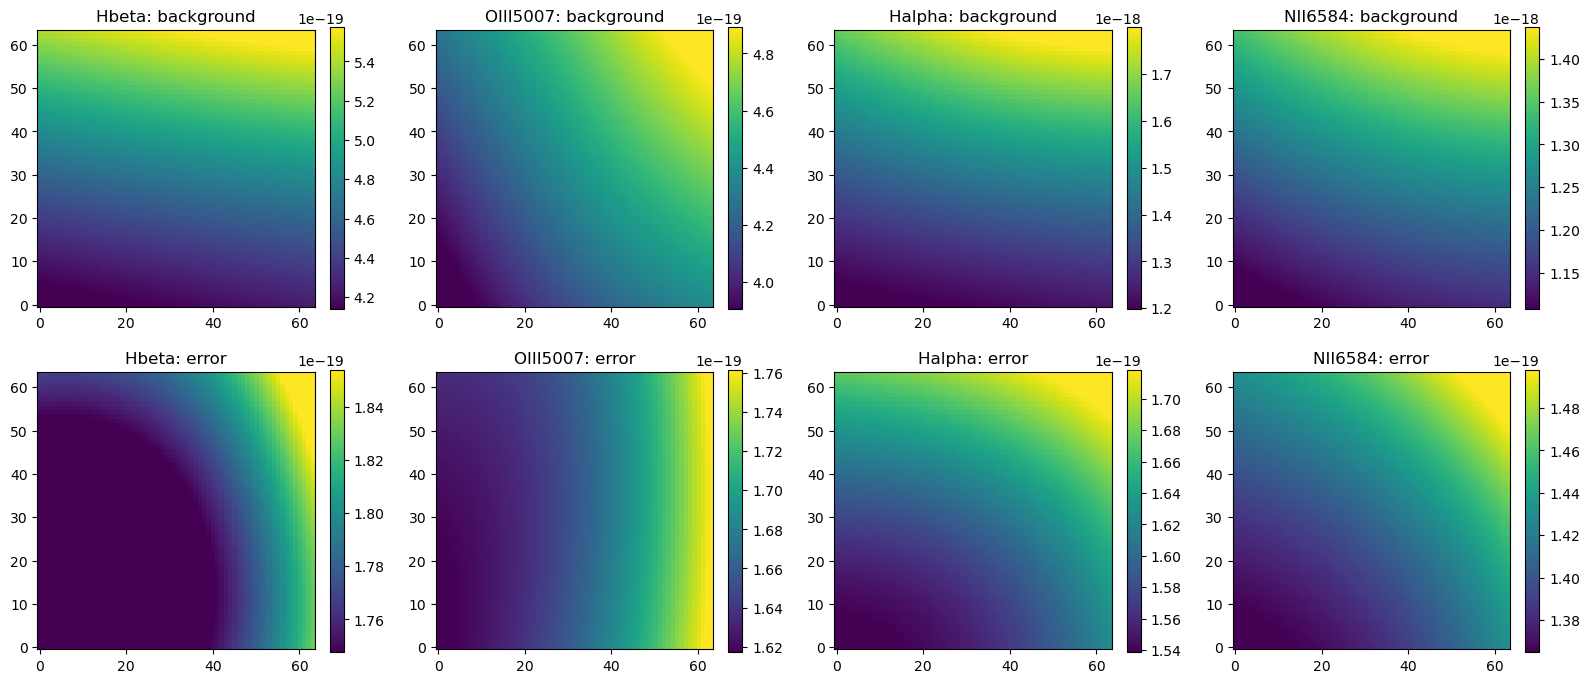

In [53]:
# ============================================================
# Inspect one background crop
# ============================================================

background_rng = np.random.default_rng(SEED)

example_background, example_error_maps, example_background_origin = extract_background_patch(
    rng=background_rng,
)

print("Example background origin (y, x):", example_background_origin)
print("Background shape:", example_background.shape)
print("Error-map shape:", example_error_maps.shape)


fig, axes = plt.subplots(2, len(USED_LINES), figsize=(16, 7))

for channel, line_name in enumerate(USED_LINES):
    background_image = example_background[channel]
    error_image = example_error_maps[channel]

    bmin, bmax = np.percentile(background_image, [2, 98])
    emin, emax = np.percentile(error_image, [2, 98])

    im = axes[0, channel].imshow(
        background_image,
        origin="lower",
        vmin=bmin,
        vmax=bmax,
    )
    axes[0, channel].set_title(f"{line_name}: background")
    plt.colorbar(im, ax=axes[0, channel], fraction=0.046)

    im = axes[1, channel].imshow(
        error_image,
        origin="lower",
        vmin=emin,
        vmax=emax,
    )
    axes[1, channel].set_title(f"{line_name}: error")
    plt.colorbar(im, ax=axes[1, channel], fraction=0.046)

plt.tight_layout()
plt.savefig("pn??.png")
plt.show()


In [44]:
# ============================================================
# Noise model
# ============================================================

def add_noise_to_maps(clean_maps, error_maps, rng):
    """Add independent Gaussian noise using the per-pixel line-error maps."""

    if clean_maps.shape != error_maps.shape:
        raise ValueError("clean_maps and error_maps must have the same shape.")

    standard_normal = rng.standard_normal(clean_maps.shape).astype(np.float32)

    return (
        clean_maps.astype(np.float32, copy=False)
        + standard_normal * error_maps.astype(np.float32, copy=False)
    ).astype(np.float32)


In [45]:
# ============================================================
# Optional fixed background
# ============================================================

fixed_background = None
fixed_error_maps = None
fixed_background_origin = None

if not REGENERATE_BACKGROUND_PER_SAMPLE:
    fixed_rng = np.random.default_rng(SEED)

    fixed_background, fixed_error_maps, fixed_background_origin = extract_background_patch(
        rng=fixed_rng,
    )

    print("Fixed background origin (y, x):", fixed_background_origin)


## Create one training sample

The background crop and its error crop come from the same spatial location. The PN signal is injected into the clean diffuse background first; noise is then drawn independently for each pixel from the matching four-channel error maps.


In [46]:
def create_training_sample(
    pn_models,
    hii_models,
    snr_models,
    rng,
    fixed_background=None,
    fixed_error_maps=None,
    fixed_background_origin=None,
):
    if REGENERATE_BACKGROUND_PER_SAMPLE:
        background_maps, error_maps, background_origin = extract_background_patch(
            rng=rng,
        )
    else:
        if fixed_background is None or fixed_error_maps is None:
            raise ValueError(
                "fixed_background and fixed_error_maps must be provided when "
                "REGENERATE_BACKGROUND_PER_SAMPLE is False."
            )

        background_maps = fixed_background.copy()
        error_maps = fixed_error_maps.copy()
        background_origin = fixed_background_origin

    # Separate maps make it easy to verify what is used as signal vs distractor.
    pn_only_maps = np.zeros_like(background_maps, dtype=np.float32)
    hii_only_maps = np.zeros_like(background_maps, dtype=np.float32)
    snr_only_maps = np.zeros_like(background_maps, dtype=np.float32)

    # PN count remains exactly 0, 1, or 2 with the original probabilities.
    n_pn = int(rng.choice(PN_NUMBERS, p=PN_PROBABILITIES))

    # Distractor counts are sampled independently.
    n_hii = int(rng.choice(HII_NUMBERS, p=HII_PROBABILITIES))
    n_snr = int(rng.choice(SNR_NUMBERS, p=SNR_PROBABILITIES))

    # One minimum-separation value is drawn per sample from U(3, 15) pix.
    minimum_separation_pix = float(
        rng.uniform(*MINIMUM_SOURCE_SEPARATION_RANGE_PIX)
    )

    n_all_sources = n_pn + n_hii + n_snr

    # Enforce the sampled separation between every pair of injected sources,
    # regardless of whether it is PN, HII, or SNR.
    all_positions = choose_source_positions(
        n_sources=n_all_sources,
        patch_size=PATCH_SIZE,
        margin_pix=SOURCE_MARGIN_PIX,
        minimum_separation_pix=minimum_separation_pix,
        rng=rng,
    )

    pn_positions = all_positions[:n_pn]
    hii_positions = all_positions[n_pn:n_pn + n_hii]
    snr_positions = all_positions[n_pn + n_hii:]

    # One shared observational PSF width for all compact sources in this patch.
    psf_fwhm_arcsec = None
    psf_fwhm_pix = None

    if n_all_sources > 0:
        psf_fwhm_arcsec = sample_truncated_normal(
            rng=rng,
            mean=PSF_FWHM_MEAN_ARCSEC,
            standard_deviation=PSF_FWHM_STD_ARCSEC,
            limits=PSF_FWHM_LIMITS_ARCSEC,
        )

        psf_fwhm_pix = psf_fwhm_arcsec / PIXEL_SCALE_ARCSEC

    pn_sources = []
    hii_sources = []
    snr_sources = []

    # -------------------------
    # Inject PNe
    # -------------------------
    for position in pn_positions:
        model_index = int(rng.integers(0, len(pn_models)))
        model_row = pn_models.iloc[model_index]

        source_metadata = inject_psf_model_source(
            output_maps=pn_only_maps,
            model_row=model_row,
            position=position,
            source_class="PN",
            m5007_range=PN_M5007_RANGE,
            psf_fwhm_arcsec=psf_fwhm_arcsec,
            psf_fwhm_pix=psf_fwhm_pix,
            rng=rng,
        )
        pn_sources.append(source_metadata)

    # -------------------------
    # Inject HII distractors
    # -------------------------
    for position in hii_positions:
        model_index = int(rng.integers(0, len(hii_models)))
        model_row = hii_models.iloc[model_index]

        source_metadata = inject_psf_model_source(
            output_maps=hii_only_maps,
            model_row=model_row,
            position=position,
            source_class="HII",
            m5007_range=HII_M5007_RANGE,
            psf_fwhm_arcsec=psf_fwhm_arcsec,
            psf_fwhm_pix=psf_fwhm_pix,
            rng=rng,
        )
        hii_sources.append(source_metadata)

    # -------------------------
    # Inject SNR distractors
    # -------------------------
    for position in snr_positions:
        model_index = int(rng.integers(0, len(snr_models)))
        model_row = snr_models.iloc[model_index]

        source_metadata = inject_psf_model_source(
            output_maps=snr_only_maps,
            model_row=model_row,
            position=position,
            source_class="SNR",
            m5007_range=SNR_M5007_RANGE,
            psf_fwhm_arcsec=psf_fwhm_arcsec,
            psf_fwhm_pix=psf_fwhm_pix,
            rng=rng,
        )
        snr_sources.append(source_metadata)

    distractor_only_maps = hii_only_maps + snr_only_maps
    all_source_maps = pn_only_maps + distractor_only_maps

    clean_injected_maps = background_maps + all_source_maps

    # Use the matching four-channel observational-error crop.
    injected_maps = add_noise_to_maps(
        clean_maps=clean_injected_maps,
        error_maps=error_maps,
        rng=rng,
    )

    # IMPORTANT: target contains ONLY the PN centres.
    target = make_centre_heatmap(
        ny=PATCH_SIZE,
        nx=PATCH_SIZE,
        positions=pn_positions,
        sigma_pix=LABEL_SIGMA_PIX,
    )

    all_sources = pn_sources + hii_sources + snr_sources

    return {
        "background_maps": background_maps.astype(np.float32),
        "error_maps": error_maps.astype(np.float32),
        "pn_only_maps": pn_only_maps.astype(np.float32),
        "hii_only_maps": hii_only_maps.astype(np.float32),
        "snr_only_maps": snr_only_maps.astype(np.float32),
        "distractor_only_maps": distractor_only_maps.astype(np.float32),
        "all_source_maps": all_source_maps.astype(np.float32),
        "injected_maps": injected_maps.astype(np.float32),
        "target": target[None, :, :].astype(np.float32),
        "metadata": {
            # Keep n_sources/sources as PN aliases for compatibility
            # with your existing plotting code.
            "n_sources": int(n_pn),
            "sources": pn_sources,

            "n_pn": int(n_pn),
            "n_hii": int(n_hii),
            "n_snr": int(n_snr),
            "minimum_source_separation_pix": float(minimum_separation_pix),

            "background_origin_yx": (
                None
                if background_origin is None
                else [int(background_origin[0]), int(background_origin[1])]
            ),
            "psf_fwhm_arcsec": (
                None if psf_fwhm_arcsec is None else float(psf_fwhm_arcsec)
            ),
            "psf_fwhm_pix": (
                None if psf_fwhm_pix is None else float(psf_fwhm_pix)
            ),

            "pn_sources": pn_sources,
            "hii_sources": hii_sources,
            "snr_sources": snr_sources,
            "all_sources": all_sources,
        },
    }


In [47]:
sample_rng = np.random.default_rng(90)

example = create_training_sample(
    pn_models=pn_models,
    hii_models=hii_models,
    snr_models=snr_models,
    rng=sample_rng,
    fixed_background=fixed_background,
    fixed_error_maps=fixed_error_maps,
    fixed_background_origin=fixed_background_origin,
)

print("Background shape:", example["background_maps"].shape)
print("Error-map shape: ", example["error_maps"].shape)
print("Injected shape:  ", example["injected_maps"].shape)
print("Target shape:    ", example["target"].shape)
print("Background origin (y, x):", example["metadata"]["background_origin_yx"])
print()
print(
    "Counts: "
    f"PN={example['metadata']['n_pn']}, "
    f"HII={example['metadata']['n_hii']}, "
    f"SNR={example['metadata']['n_snr']}"
)
print(
    "Sampled minimum separation [pix]:",
    example["metadata"]["minimum_source_separation_pix"],
)


Background shape: (4, 64, 64)
Error-map shape:  (4, 64, 64)
Injected shape:   (4, 64, 64)
Target shape:     (1, 64, 64)
Background origin (y, x): [1019, 2343]

Counts: PN=1, HII=1, SNR=1
Sampled minimum separation [pix]: 11.963119726921152


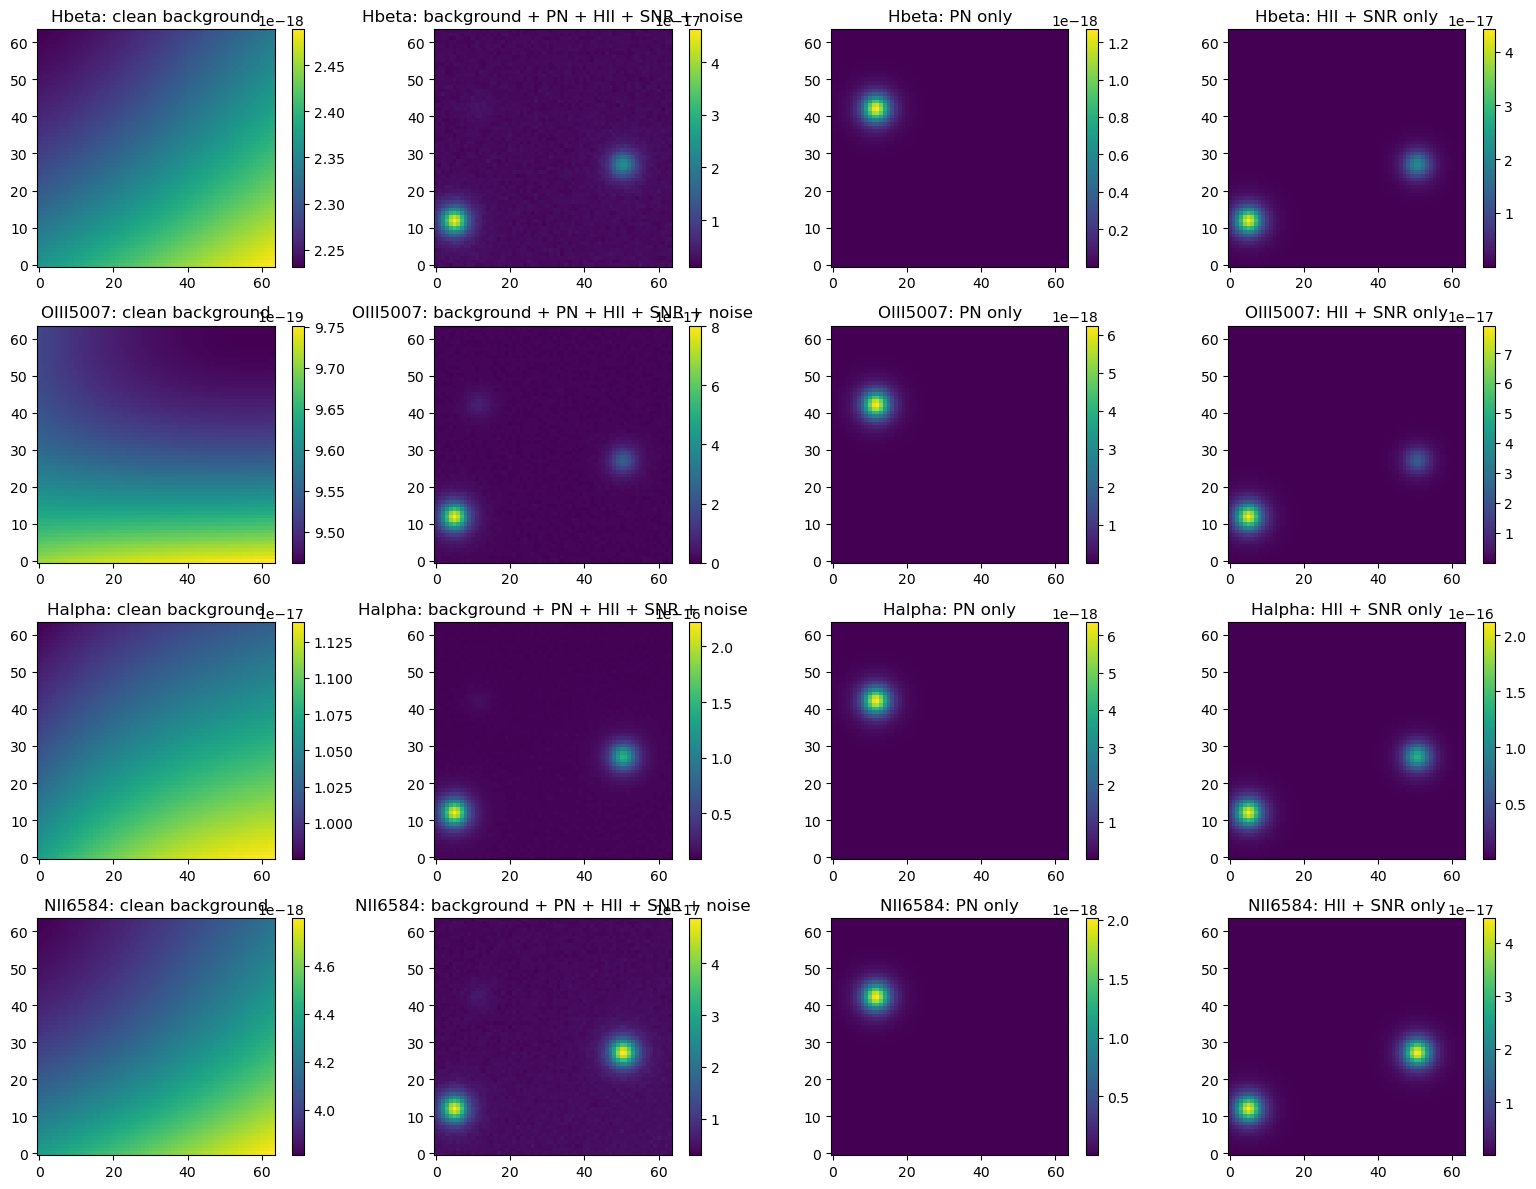

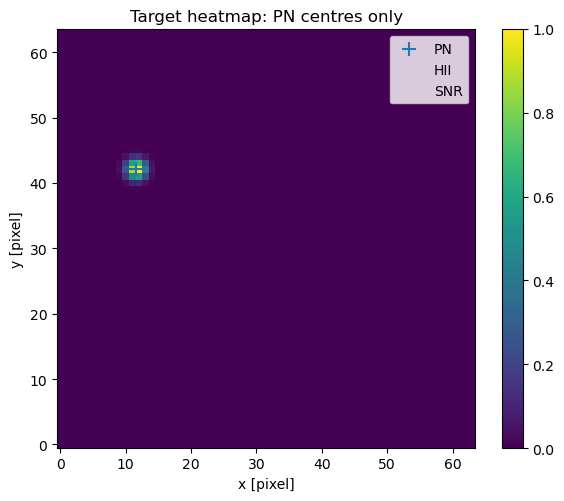

In [48]:
# Compare background, noisy injected map, PN signal, and distractor signal.

fig, axes = plt.subplots(
    len(USED_LINES),
    4,
    figsize=(16, 3 * len(USED_LINES)),
)

for channel, line_name in enumerate(USED_LINES):
    background = example["background_maps"][channel]
    injected = example["injected_maps"][channel]
    pn_only = example["pn_only_maps"][channel]
    distractor_only = example["distractor_only_maps"][channel]

    im0 = axes[channel, 0].imshow(background, origin="lower")
    axes[channel, 0].set_title(f"{line_name}: clean background")
    plt.colorbar(im0, ax=axes[channel, 0], fraction=0.046)

    im1 = axes[channel, 1].imshow(injected, origin="lower")
    axes[channel, 1].set_title(f"{line_name}: background + PN + HII + SNR + noise")
    plt.colorbar(im1, ax=axes[channel, 1], fraction=0.046)

    im2 = axes[channel, 2].imshow(pn_only, origin="lower")
    axes[channel, 2].set_title(f"{line_name}: PN only")
    plt.colorbar(im2, ax=axes[channel, 2], fraction=0.046)

    im3 = axes[channel, 3].imshow(distractor_only, origin="lower")
    axes[channel, 3].set_title(f"{line_name}: HII + SNR only")
    plt.colorbar(im3, ax=axes[channel, 3], fraction=0.046)
plt.savefig("pn?.png")
plt.tight_layout()
plt.show()


# Show that only PN positions appear in the target.
plt.figure(figsize=(6, 5))
plt.imshow(
    example["target"][0],
    origin="lower",
    vmin=0,
    vmax=1,
)

for source in example["metadata"]["pn_sources"]:
    plt.scatter(
        source["x"],
        source["y"],
        marker="+",
        s=90,
        label="PN" if "PN" not in plt.gca().get_legend_handles_labels()[1] else None,
    )

for source in example["metadata"]["hii_sources"]:
    plt.scatter(
        source["x"],
        source["y"],
        marker="o",
        facecolors="none",
        s=70,
        label="HII" if "HII" not in plt.gca().get_legend_handles_labels()[1] else None,
    )

for source in example["metadata"]["snr_sources"]:
    plt.scatter(
        source["x"],
        source["y"],
        marker="s",
        facecolors="none",
        s=70,
        label="SNR" if "SNR" not in plt.gca().get_legend_handles_labels()[1] else None,
    )

plt.title("Target heatmap: PN centres only")
plt.xlabel("x [pixel]")
plt.ylabel("y [pixel]")
plt.colorbar()
#plt.savefig("pn???.png")

handles, labels = plt.gca().get_legend_handles_labels()
if handles:
    plt.legend()

plt.tight_layout()
plt.show()


In [49]:
# ============================================================
# Dataset generation
# ============================================================

def create_dataset(
    n_samples,
    pn_models,
    hii_models,
    snr_models,
    seed,
    fixed_background=None,
    fixed_error_maps=None,
    fixed_background_origin=None,
    return_oiii_pn_only=False,
):
    rng = np.random.default_rng(seed)

    inputs = np.empty(
        (
            n_samples,
            len(USED_LINES),
            PATCH_SIZE,
            PATCH_SIZE,
        ),
        dtype=np.float32,
    )

    targets = np.empty(
        (
            n_samples,
            1,
            PATCH_SIZE,
            PATCH_SIZE,
        ),
        dtype=np.float32,
    )

    oiii_pn_only = None

    if return_oiii_pn_only:
        oiii_pn_only = np.empty(
            (n_samples, PATCH_SIZE, PATCH_SIZE),
            dtype=np.float32,
        )
        oiii_channel = USED_LINES.index("OIII5007")

    metadata = []

    for sample_index in range(n_samples):
        sample = create_training_sample(
            pn_models=pn_models,
            hii_models=hii_models,
            snr_models=snr_models,
            rng=rng,
            fixed_background=fixed_background,
            fixed_error_maps=fixed_error_maps,
            fixed_background_origin=fixed_background_origin,
        )

        inputs[sample_index] = sample["injected_maps"]
        targets[sample_index] = sample["target"]
        metadata.append(sample["metadata"])

        if return_oiii_pn_only:
            oiii_pn_only[sample_index] = sample["pn_only_maps"][oiii_channel]

        if sample_index == 0 or (sample_index + 1) % 100 == 0:
            print(f"Generated {sample_index + 1}/{n_samples}")

    if return_oiii_pn_only:
        return inputs, targets, metadata, oiii_pn_only

    return inputs, targets, metadata


def normalize_inputs_inplace(inputs, channel_means=None, channel_stds=None):
    """Standardize each emission-line channel over samples and spatial pixels.

    For validation or test data, pass the means and standard deviations computed
    from the training data instead of calculating new values.
    """

    if inputs.ndim != 4:
        raise ValueError("inputs must have shape (samples, channels, y, x).")

    n_channels = inputs.shape[1]

    if channel_means is None:
        channel_means = np.array(
            [
                np.mean(inputs[:, channel], dtype=np.float64)
                for channel in range(n_channels)
            ],
            dtype=np.float64,
        )
    else:
        channel_means = np.asarray(channel_means, dtype=np.float64)

    if channel_stds is None:
        channel_stds = np.array(
            [
                np.std(inputs[:, channel], dtype=np.float64)
                for channel in range(n_channels)
            ],
            dtype=np.float64,
        )
    else:
        channel_stds = np.asarray(channel_stds, dtype=np.float64)

    if channel_means.shape != (n_channels,):
        raise ValueError("channel_means must contain one value per channel.")

    if channel_stds.shape != (n_channels,):
        raise ValueError("channel_stds must contain one value per channel.")

    if np.any(~np.isfinite(channel_means)):
        raise ValueError("channel_means contains non-finite values.")

    if np.any(~np.isfinite(channel_stds)) or np.any(channel_stds <= 0):
        raise ValueError(
            "Every channel standard deviation must be finite and positive."
        )

    for channel in range(n_channels):
        np.subtract(
            inputs[:, channel],
            channel_means[channel],
            out=inputs[:, channel],
        )
        np.divide(
            inputs[:, channel],
            channel_stds[channel],
            out=inputs[:, channel],
        )

    return channel_means, channel_stds


In [50]:
# Start with a preview/training dataset.

preview_X, preview_Y, preview_metadata, preview_oiii_pn_only = create_dataset(
    n_samples=10000,
    pn_models=pn_models,
    hii_models=hii_models,
    snr_models=snr_models,
    seed=200,
    fixed_background=fixed_background,
    fixed_error_maps=fixed_error_maps,
    fixed_background_origin=fixed_background_origin,
    return_oiii_pn_only=True,
)

# Calculate these statistics from the training set only.
# Reuse the same values later for validation, test, and real observations.
preview_channel_means, preview_channel_stds = normalize_inputs_inplace(preview_X)

print("X shape:", preview_X.shape)
print("Y shape:", preview_Y.shape)
print("X size [MB]:", preview_X.nbytes / 1024**2)

print()
print("Normalization statistics:")

for line_name, mean, std in zip(
    USED_LINES,
    preview_channel_means,
    preview_channel_stds,
):
    print(f"{line_name:10s}: mean={mean:.4e}, std={std:.4e}")


Generated 1/10000
Generated 100/10000
Generated 200/10000
Generated 300/10000
Generated 400/10000
Generated 500/10000
Generated 600/10000
Generated 700/10000
Generated 800/10000
Generated 900/10000
Generated 1000/10000
Generated 1100/10000
Generated 1200/10000
Generated 1300/10000
Generated 1400/10000
Generated 1500/10000
Generated 1600/10000
Generated 1700/10000
Generated 1800/10000
Generated 1900/10000
Generated 2000/10000
Generated 2100/10000
Generated 2200/10000
Generated 2300/10000
Generated 2400/10000
Generated 2500/10000
Generated 2600/10000
Generated 2700/10000
Generated 2800/10000
Generated 2900/10000
Generated 3000/10000
Generated 3100/10000
Generated 3200/10000
Generated 3300/10000
Generated 3400/10000
Generated 3500/10000
Generated 3600/10000
Generated 3700/10000
Generated 3800/10000
Generated 3900/10000
Generated 4000/10000
Generated 4100/10000
Generated 4200/10000
Generated 4300/10000
Generated 4400/10000
Generated 4500/10000
Generated 4600/10000
Generated 4700/10000
Gene

## Inspect normalized examples

Samples containing PNe: 7522


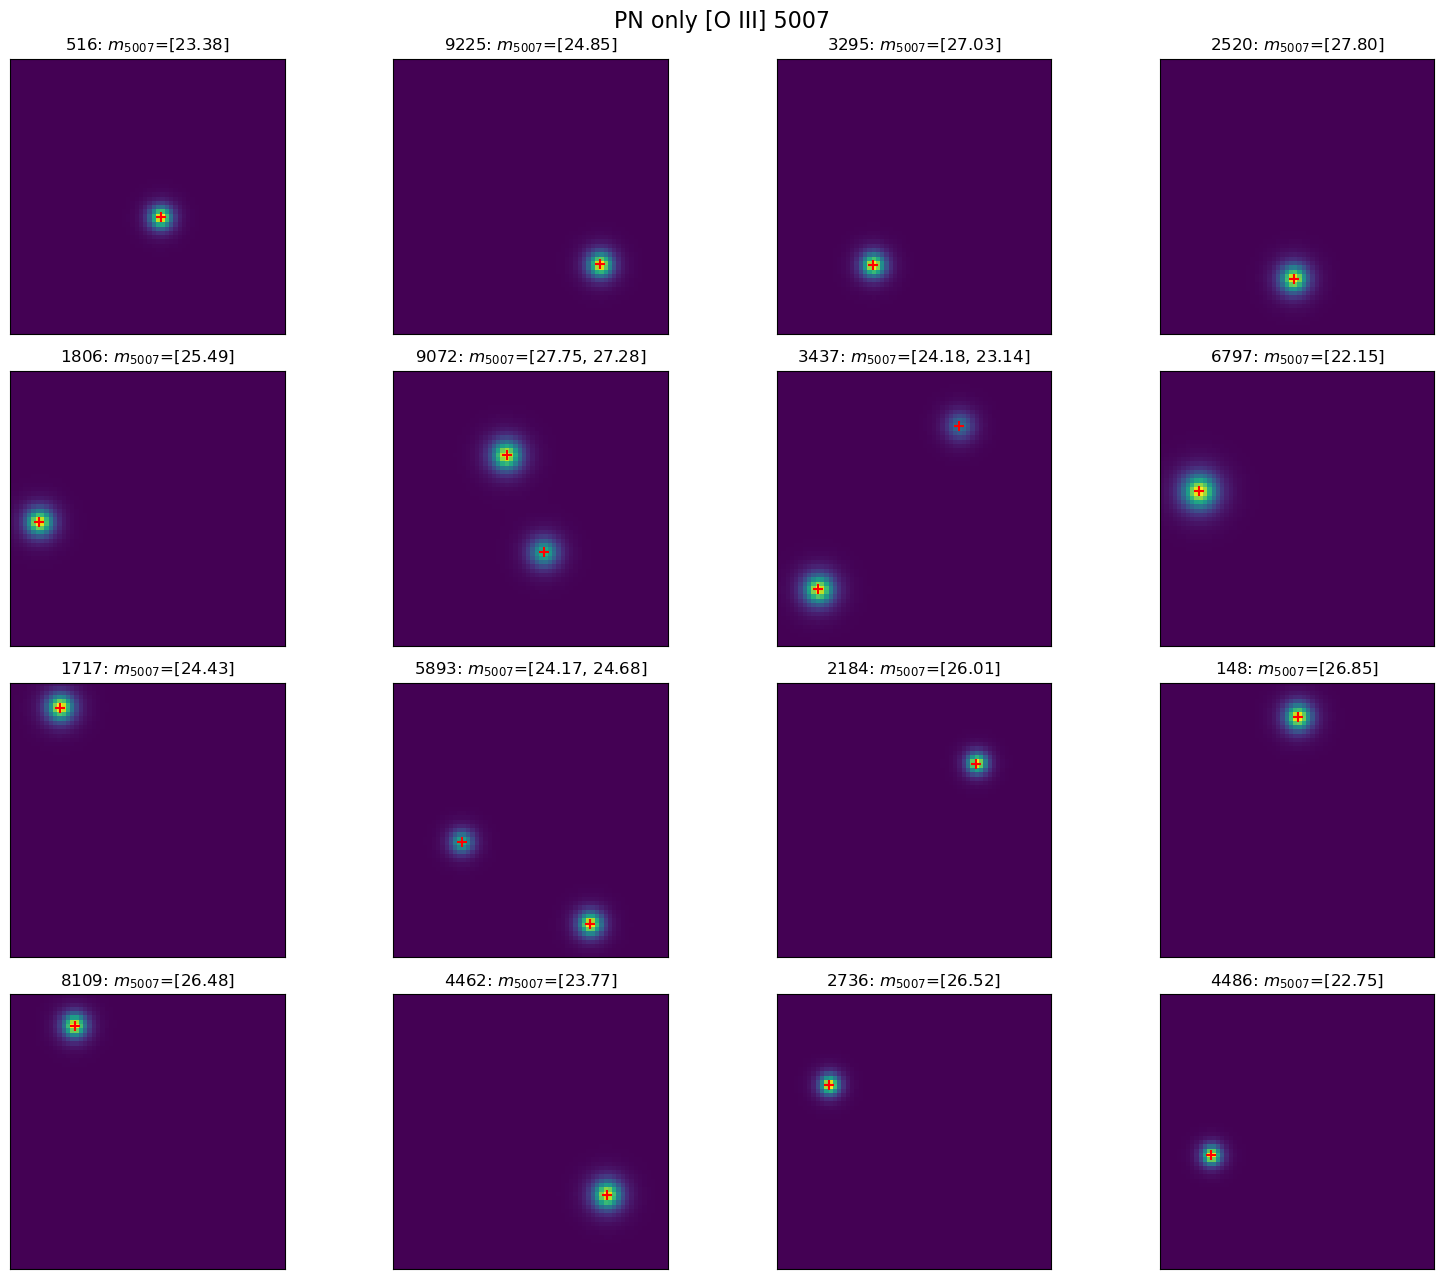

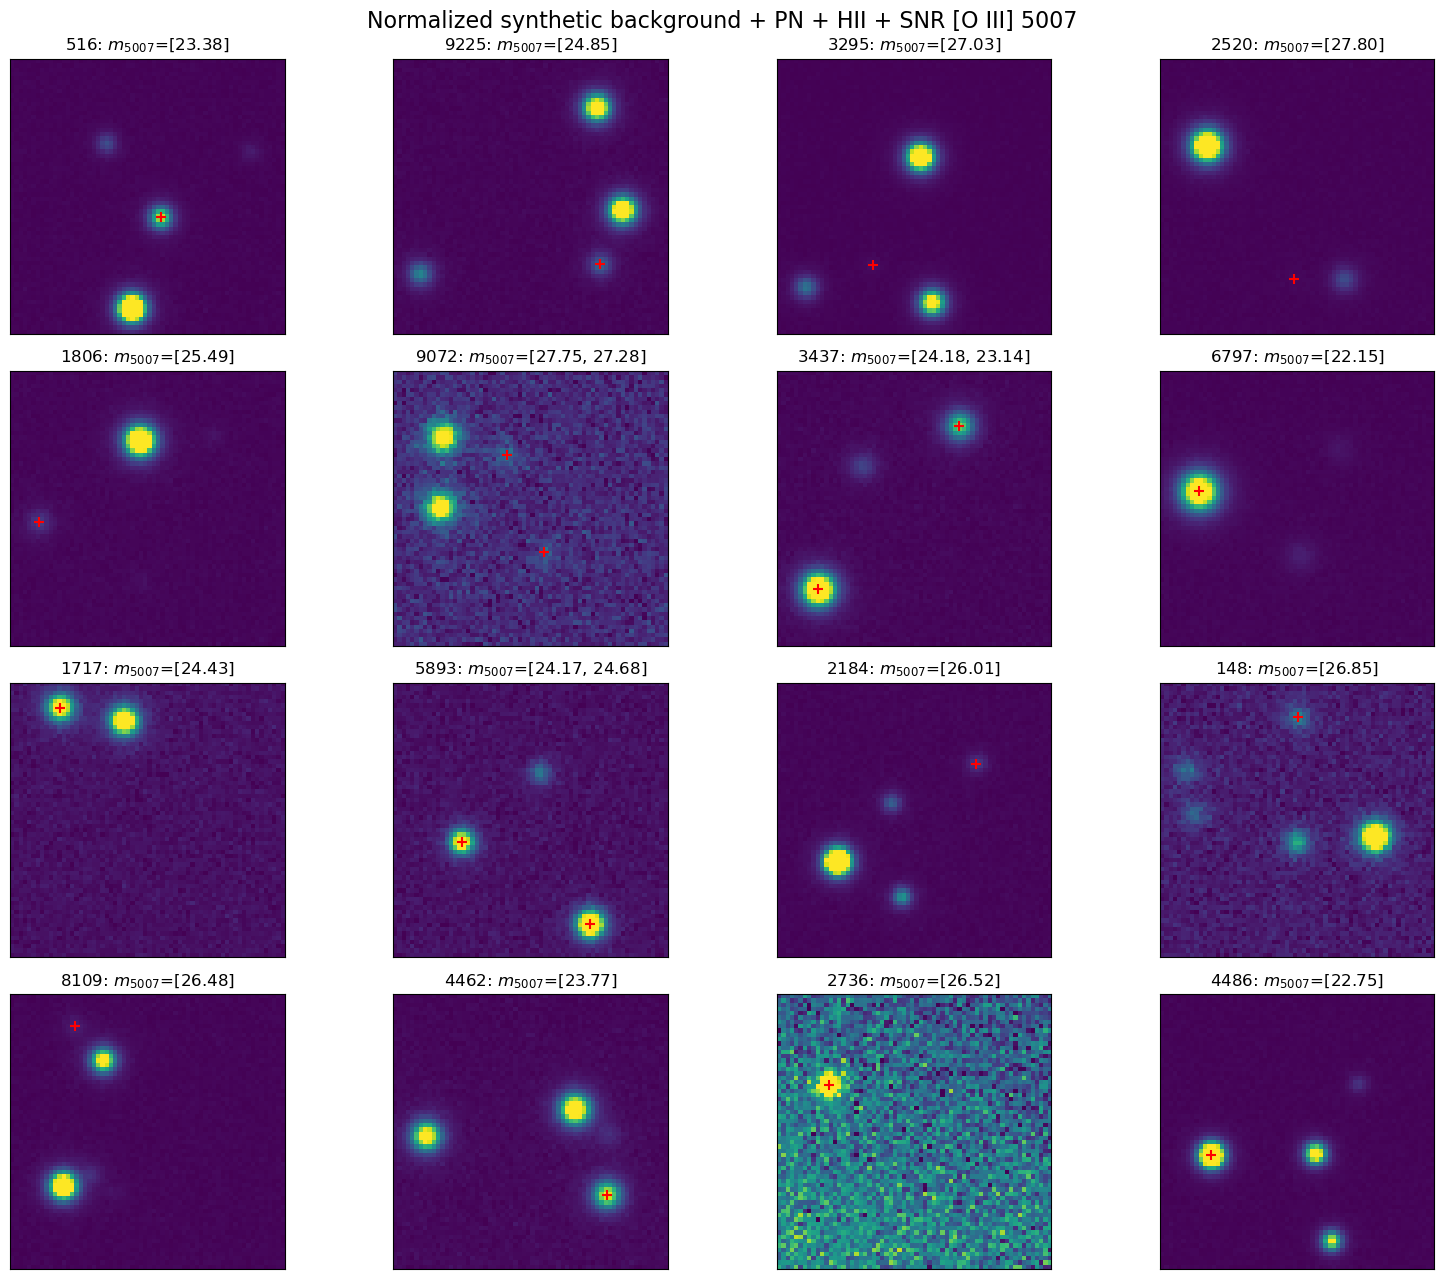

In [51]:
n_show = min(10, len(preview_X))

oiii_channel = USED_LINES.index("OIII5007")

plot_rng = np.random.default_rng(33)
# Indices of samples containing at least one PN
pn_sample_indices = np.array([
    i
    for i, metadata in enumerate(preview_metadata)
    if len(metadata["sources"]) > 0
])

n_show = min(16, len(pn_sample_indices))

plot_rng = np.random.default_rng(123)

sample_indices = plot_rng.choice(
    pn_sample_indices,
    size=n_show,
    replace=False,
)

print(f"Samples containing PNe: {len(pn_sample_indices)}")

fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 13),
)

axes = axes.ravel()

for axis, sample_index in zip(
    axes,
    sample_indices,
):
    oiii_pn_only = preview_oiii_pn_only[sample_index]
    sources = preview_metadata[sample_index]["sources"]

    im = axis.imshow(
        oiii_pn_only,
        origin="lower",
        vmin=0.0,
        vmax=np.max(oiii_pn_only),
    )

    for source in sources:
        axis.scatter(
            source["x"],
            source["y"],
            marker="+",
            color="r",
            s=50,
            linewidths=1.5,
        )

    magnitudes = ", ".join(f'{source["m5007"]:.2f}' for source in sources)
    axis.set_title(f'{sample_index}: $m_{{5007}}$=[{magnitudes}]')
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle("PN only [O III] 5007", fontsize=16)
plt.tight_layout()
plt.savefig('pn1')
plt.show()

# ============================================================
# Plot the same [O III] background + PN maps
# ============================================================

fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 13),
)

axes = axes.ravel()

for axis, sample_index in zip(
    axes,
    sample_indices,
):
    oiii_with_background = preview_X[
        sample_index,
        oiii_channel,
    ]

    sources = preview_metadata[sample_index]["sources"]

    vmin = np.percentile(
        oiii_with_background,
        1,
    )

    vmax = np.percentile(
        oiii_with_background,
        99.5,
    )

    im = axis.imshow(
        oiii_with_background,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    for source in sources:
        axis.scatter(
            source["x"],
            source["y"],
            marker="+",
            color="r",
            s=50,
            linewidths=1.5,
        )

    magnitudes = ", ".join(f'{source["m5007"]:.2f}' for source in sources)
    axis.set_title(f'{sample_index}: $m_{{5007}}$=[{magnitudes}]')
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle(
    "Normalized synthetic background + PN + HII + SNR [O III] 5007",
    fontsize=16,
)

plt.tight_layout()
plt.savefig('pn2')
plt.show()

## Save the normalized dataset

In [52]:
def save_dataset(
    output_path,
    inputs,
    targets,
    metadata,
    channel_means,
    channel_stds):
    output_path = Path(output_path)

    np.savez_compressed(
        output_path,
        X=inputs,
        Y=targets,
        line_names=np.asarray(USED_LINES),
        channel_means=np.asarray(channel_means, dtype=np.float64),
        channel_stds=np.asarray(channel_stds, dtype=np.float64),
        metadata_json=np.asarray(json.dumps(metadata)))

    print("Saved:", output_path.resolve())


save_dataset(
    output_path="fully_synthetic_PN_10000_norm.npz",
    inputs=preview_X,
    targets=preview_Y,
    metadata=preview_metadata,
    channel_means=preview_channel_means,
    channel_stds=preview_channel_stds)

Saved: /Users/golta/Desktop/Uni/Thesis/PN/fully_synthetic_PN_10000_norm.npz
